TRƯỜNG ĐẠI HỌC KỸ THUẬT - CÔNG NGHỆ CẦN THƠ
KHOA CÔNG NGHỆ THÔNG TIN
BỘ MÔN KHOA HỌC DỮ LIỆU	ĐỀ THI GIỮA KỲ THỰC HÀNH
HỌC KỲ I - NĂM HỌC 2026 - 2027
Môn: Phân tích và Trực quan Dữ liệu
Lớp học phần: CNTT_1
Giảng viên ra đề: TS. Lý Hồng Hải
Thời gian làm bài: 60 phút	Hình thức: Thi trên máy tính
Tập dữ liệu: bank-additional-full.csv
Sử dụng tài liệu: Không được sử dụng

Họ Tên: Phạm Quang Minh
MSSV:CNTT2411082


Phần 1: Tiền xử lý dữ liệu (2 điểm)

1 (1 điểm): Đọc dữ liệu vào DataFrame, hiển thị 5 dòng đầu, thống kê tổng quan.
Gợi ý: sử dụng pd.read_csv(...), df.head(), df.info(), df.describe().


In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

df = pd.read_csv('bank-additional-full.csv', sep=';')
print('Kích thước dữ liệu:', df.shape)
df.info

Kích thước dữ liệu: (41188, 21)


<bound method DataFrame.info of        age          job  marital            education  default housing loan  \
0       56    housemaid  married             basic.4y       no      no   no   
1       57     services  married          high.school  unknown      no   no   
2       37     services  married          high.school       no     yes   no   
3       40       admin.  married             basic.6y       no      no   no   
4       56     services  married          high.school       no      no  yes   
...    ...          ...      ...                  ...      ...     ...  ...   
41183   73      retired  married  professional.course       no     yes   no   
41184   46  blue-collar  married  professional.course       no      no   no   
41185   56      retired  married    university.degree       no     yes   no   
41186   44   technician  married  professional.course       no      no   no   
41187   74      retired  married  professional.course       no     yes   no   

         contact mo

2 (1 điểm): Kiểm tra dữ liệu thiếu và thống kê số lượng giá trị 'unknown' theo từng cột.
Gợi ý: sử dụng df.isna().sum() và df[col] == 'unknown'.


In [73]:
print('Số giá trị NaN theo cột:')
print(df.isna().sum())
unknown_cnt = (df == 'unknown').sum()
unknown_df = pd.DataFrame({'So_luong_unknown': unknown_cnt,
                           'Ty_le_%': (unknown_cnt / len(df) * 100).round(2)})
unknown_df[unknown_df.So_luong_unknown > 0].sort_values('So_luong_unknown', ascending=False)

Số giá trị NaN theo cột:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


,So_luong_unknown,Ty_le_%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


Phần 2: Trực quan hóa dữ liệu (6 điểm)

3 (1 điểm): Vẽ biểu đồ cột thể hiện phân bố khách hàng theo 'job'.
Gợi ý: sử dụng sns.countplot(...), có thể xoay nhãn trục X.


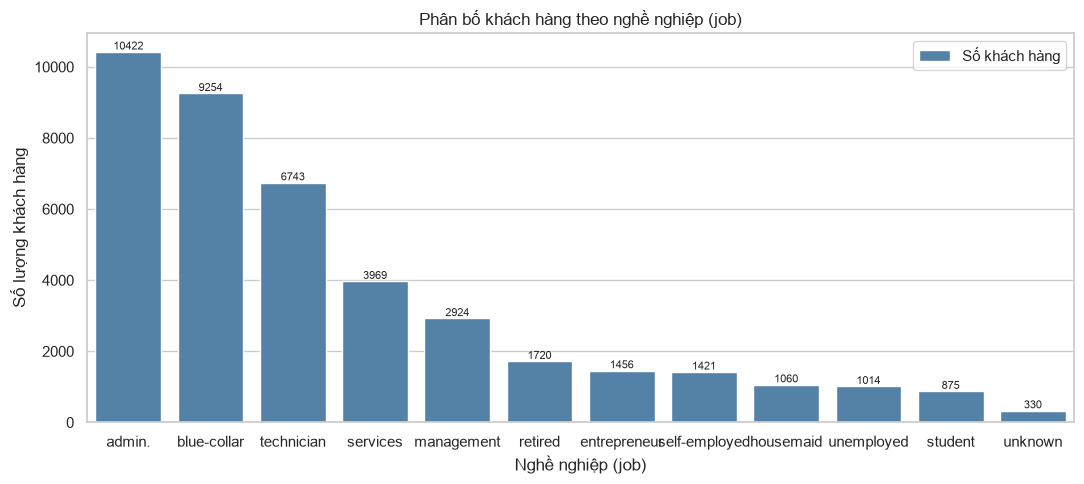

In [74]:
plt.figure(figsize=(11, 5))
order = df['job'].value_counts().index
ax = sns.countplot(x='job', data=df, order=order, color='steelblue', label='Số khách hàng')
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.title('Phân bố khách hàng theo nghề nghiệp (job)')
plt.xlabel('Nghề nghiệp (job)')
plt.ylabel('Số lượng khách hàng')
plt.legend()
plt.tight_layout()
plt.show()

4 (1 điểm): Vẽ boxplot so sánh 'age' theo biến mục tiêu 'y'.
Gợi ý: dùng sns.boxplot(x='y', y='age', data=df).


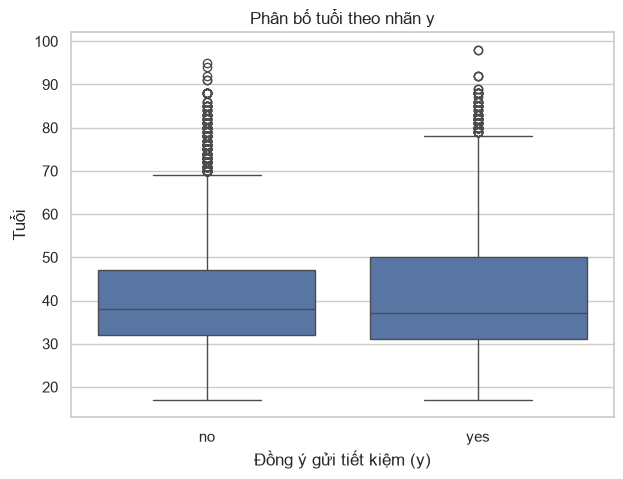

      mean  median    std
y                        
no   39.91    38.0   9.90
yes  40.91    37.0  13.84


In [75]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='y', y='age', data=df)
plt.title('Phân bố tuổi theo nhãn y')
plt.xlabel('Đồng ý gửi tiết kiệm (y)')
plt.ylabel('Tuổi')
plt.show()

print(df.groupby('y')['age'].agg(['mean', 'median', 'std']).round(2))


5 (1 điểm): Vẽ scatter plot giữa 'duration' và 'campaign', màu theo 'y'.
Gợi ý: sns.scatterplot(x='duration', y='campaign', hue='y', data=df).


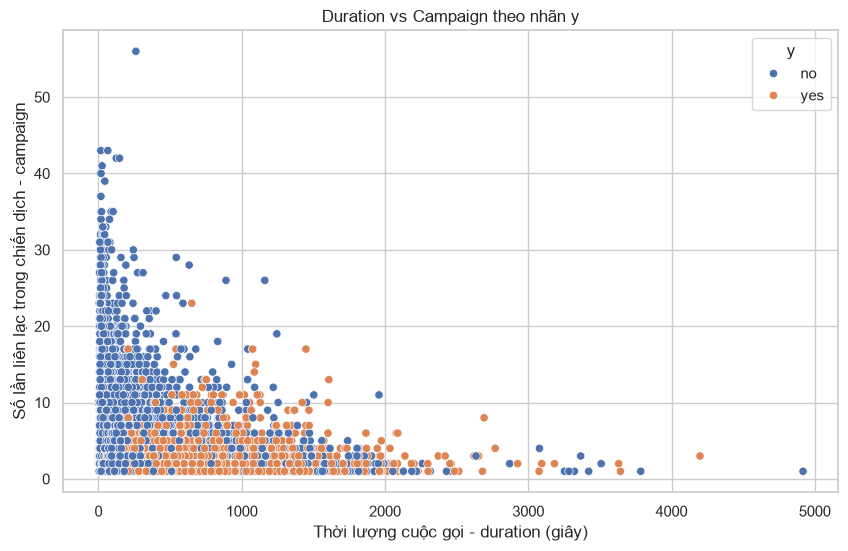

In [76]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='duration', y='campaign', hue='y', data=df,)
plt.title('Duration vs Campaign theo nhãn y')
plt.xlabel('Thời lượng cuộc gọi - duration (giây)')
plt.ylabel('Số lần liên lạc trong chiến dịch - campaign')
plt.legend(title='y')
plt.show()

6 (1 điểm): Vẽ heatmap số mẫu theo 'education' và 'marital'.
Gợi ý: dùng pd.crosstab(...) và sns.heatmap(...).


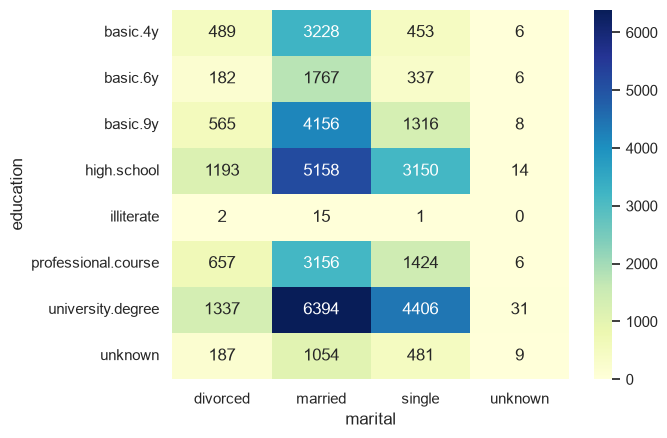

In [77]:
ct = pd.crosstab(df['education'], df['marital'])
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu')
plt.show()


7 (1 điểm): Vẽ Treemap thể hiện số mẫu theo 'job' và 'y'.
Gợi ý: nhóm bằng groupby, sau đó dùng squarify.plot(...).


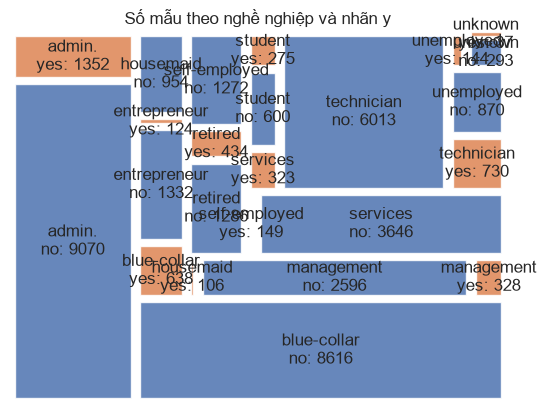

In [78]:
g = df.groupby(['job', 'y']).size().reset_index(name='n')

squarify.plot(
    sizes=g['n'],
    label=[f"{job}\n{y}: {n}" for job, y, n in zip(g['job'], g['y'], g['n'])],
    color=g['y'].map({'no': '#4C72B0', 'yes': '#DD8452'}),
    alpha=0.85,
    pad=True
)
plt.title('Số mẫu theo nghề nghiệp và nhãn y')
plt.axis('off')
plt.show()


8 (1 điểm): Vẽ biểu đồ Pie thể hiện tỷ lệ nhãn 'y'.
Gợi ý: dùng value_counts().plot.pie(...).


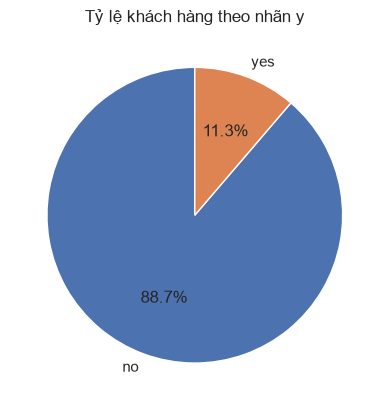

In [79]:
counts.plot.pie(
    autopct='%1.1f%%',
    colors=['#4C72B0', '#DD8452'],
    startangle=90,
    title='Tỷ lệ khách hàng theo nhãn y'
)
plt.ylabel('')
plt.show()

Phần 3: Nhận xét kết quả (2 điểm)

9 (1 điểm): Nhóm khách hàng nào có tuổi trung bình cao hơn? Gợi ý điều gì?
Gợi ý: Quan sát boxplot từ câu 4.


In [80]:
print(df.groupby('y')['age'].agg(['count', 'mean', 'median', 'std']).round(2))

     count   mean  median    std
y                               
no   36548  39.91    38.0   9.90
yes   4640  40.91    37.0  13.84


**Trả lời:** Nhóm **y = yes** có tuổi trung bình cao hơn một chút (**≈ 40.9** so với **≈ 39.9** của nhóm *no*; chênh lệch ~1 tuổi). Median thì ngược lại (*yes* = 37, *no* = 38) nên sự khác biệt về tâm là **rất nhỏ**.

10 (1 điểm - Phân loại nâng cao): Dựa vào Scatter Plot ở câu 5, hãy phân tích tác động tương quan giữa 'thời lượng cuộc gọi' (duration) và 'số lần liên lạc trong chiến dịch' (campaign) đối với khả năng khách hàng đồng ý gửi tiết kiệm (y = 'yes'). Từ đó, hãy đề xuất quy tắc tối ưu cho tư vấn viên để nâng cao tỷ lệ chốt hợp đồng thành công.